In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/meherunnesanithi/friday-workinghours-afternoon-ddos-pcap-iscx/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


## Cell 1: Import Libraries

In [2]:

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

try:
    import shap
except ImportError:
    %pip install -q shap
    import shap

from sklearn import set_config
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc, classification_report,
                             ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams.update({"figure.figsize": (10, 6), "font.size": 12,
                     "axes.titlesize": 15, "axes.titleweight": "bold"})
set_config(display="diagram")

RS = 42
TARGET = "Label"
CLASS_NAMES = ["BENIGN", "DDoS"]
N_FEATURES = 25
GAP_LIMIT = 0.005
print("✅ Libraries imported")

✅ Libraries imported


## Cell 2 : Load Dataset

In [3]:
df = pd.read_csv("/kaggle/input/datasets/meherunnesanithi/friday-workinghours-afternoon-ddos-pcap-iscx/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")
df.columns = df.columns.str.strip()
print("Shape:", df.shape)
df.head()

Shape: (225745, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## cell 3 : Data Quality Check

In [4]:
num_df = df.select_dtypes("number")
quality = pd.Series({
    "Missing values (NaN)":       int(df.isnull().sum().sum()),
    "Infinite values (inf)":      int(np.isinf(num_df).sum().sum()),
    "Duplicate rows":             int(df.duplicated().sum()),
    "Constant columns (1 value)": int((num_df.nunique() <= 1).sum()),
}, name="Count")
display(quality.to_frame())

print("\nColumns containing NaN / inf:")
bad = pd.DataFrame({"NaN": df.isnull().sum(), "inf": np.isinf(num_df).sum()})
display(bad[(bad > 0).any(axis=1)])

print("\nClass counts:")
display(df[TARGET].value_counts().to_frame("Rows"))

,Count
Missing values (NaN),4
Infinite values (inf),64
Duplicate rows,2633
Constant columns (1 value),10



Columns containing NaN / inf:


,NaN,inf
Flow Bytes/s,4,30.0
Flow Packets/s,0,34.0



Class counts:


,Rows
Label,
DDoS,128027
BENIGN,97718


## Cell 4 :EDA - Class distribution

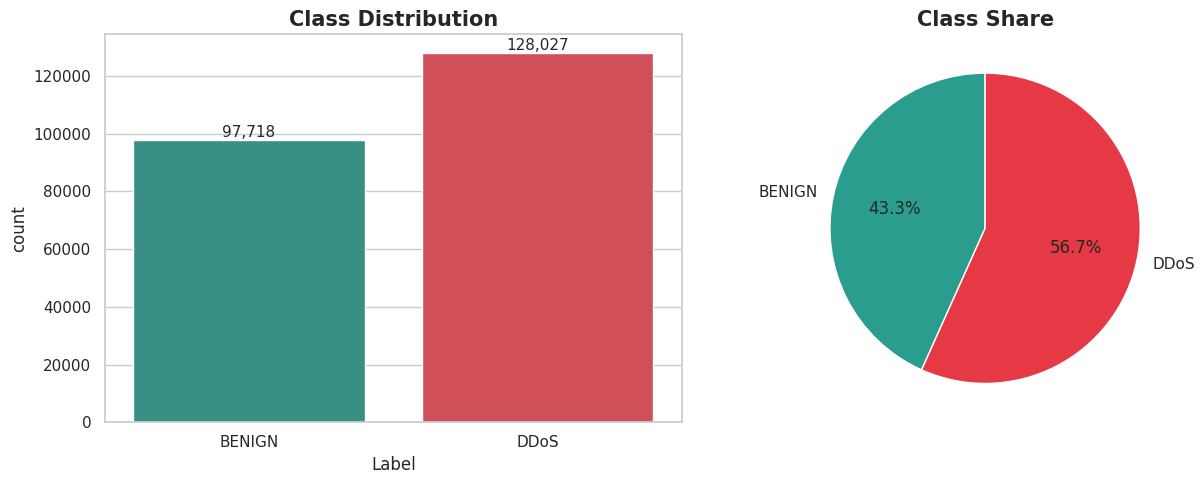

In [5]:
eda = df.replace([np.inf, -np.inf], np.nan).copy()
eda["y"] = eda[TARGET].map({"BENIGN": 0, "DDoS": 1})

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(x=TARGET, data=eda, order=CLASS_NAMES, ax=ax[0], palette=["#2a9d8f", "#e63946"])
ax[0].set_title("Class Distribution")
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                   ha="center", va="bottom", fontsize=11)
eda[TARGET].value_counts().reindex(CLASS_NAMES).plot.pie(
    autopct="%1.1f%%", colors=["#2a9d8f", "#e63946"], startangle=90, ax=ax[1], ylabel="")
ax[1].set_title("Class Share")
plt.tight_layout(); plt.show()

## Cell 5: Data preprocessing

In [6]:
n0 = len(df)
df = df.replace([np.inf, -np.inf], np.nan)
df = df.drop_duplicates().reset_index(drop=True)
const_cols = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
df = df.drop(columns=const_cols)
df[TARGET] = df[TARGET].map({"BENIGN": 0, "DDoS": 1})

print(f"Duplicates removed  : {n0 - len(df):,}")
print(f"Constant columns    : {len(const_cols)} dropped")
print(f"Shape after cleaning: {df.shape}")
print("Remaining NaN cells :", int(df.isnull().sum().sum()), "(imputed after the split)")

X = df.drop(columns=TARGET)
y = df[TARGET]
print("\nFeatures:", X.shape[1])
print(y.value_counts().rename({0: "BENIGN", 1: "DDoS"}).to_string())

Duplicates removed  : 2,633
Constant columns    : 10 dropped
Shape after cleaning: (223112, 69)
Remaining NaN cells : 60 (imputed after the split)

Features: 68
Label
DDoS      128016
BENIGN     95096


## Cell 6: Train-Test Split 

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RS)

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print("DDoS share -> train: {:.3f} | test: {:.3f}".format(y_train.mean(), y_test.mean()))

Train: (178489, 68)   Test: (44623, 68)
DDoS share -> train: 0.574 | test: 0.574


## Cell 7:RFE 

In [8]:
def make_prep():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
        ("rfe",     RFE(LogisticRegression(max_iter=300), n_features_to_select=N_FEATURES, step=10)),
    ])

prep = make_prep()
X_train_f = prep.fit_transform(X_train, y_train)     # fit on train
X_test_f  = prep.transform(X_test)                   # test only transform

selected = X.columns[prep.named_steps["rfe"].support_]
X_train_f = pd.DataFrame(X_train_f, columns=selected, index=X_train.index)
X_test_f  = pd.DataFrame(X_test_f,  columns=selected, index=X_test.index)

print(f"Features: {X.shape[1]}  ->  {len(selected)} selected by RFE\n")
display(pd.Series(selected, name="Selected features").to_frame())
prep

Features: 68  ->  25 selected by RFE



,Selected features
0,Destination Port
1,Flow Duration
2,Total Fwd Packets
3,Total Backward Packets
4,Total Length of Fwd Packets
5,Total Length of Bwd Packets
6,Flow IAT Mean
7,Flow IAT Std
8,Fwd IAT Total
9,Fwd IAT Min


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('rfe',
                 RFE(estimator=LogisticRegression(max_iter=300),
                     n_features_to_select=25, step=10))])

## Cell 8 : Base Models + Evaluation

In [9]:

def evaluate(name, model, Xte, yte):
    pred  = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    return {"Model": name,
            "Accuracy":  accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, average="weighted"),
            "Recall":    recall_score(yte, pred, average="weighted"),
            "F1":        f1_score(yte, pred, average="weighted"),
            "ROC-AUC":   roc_auc_score(yte, proba)}

base = {
    "Naive Bayes":         GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree":       DecisionTreeClassifier(random_state=RS),
}
results = []
for name, model in base.items():
    model.fit(X_train_f, y_train)
    results.append(evaluate(name, model, X_test_f, y_test))

res_base = pd.DataFrame(results).set_index("Model")
res_base.style.background_gradient(cmap="Greens", axis=None).format("{:.4f}")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Naive Bayes,0.8504,0.8811,0.8504,0.8431,0.8478
Logistic Regression,0.9985,0.9985,0.9985,0.9985,0.9998
Decision Tree,0.9997,0.9997,0.9997,0.9997,0.9997


## Cell 9: : Base model chart

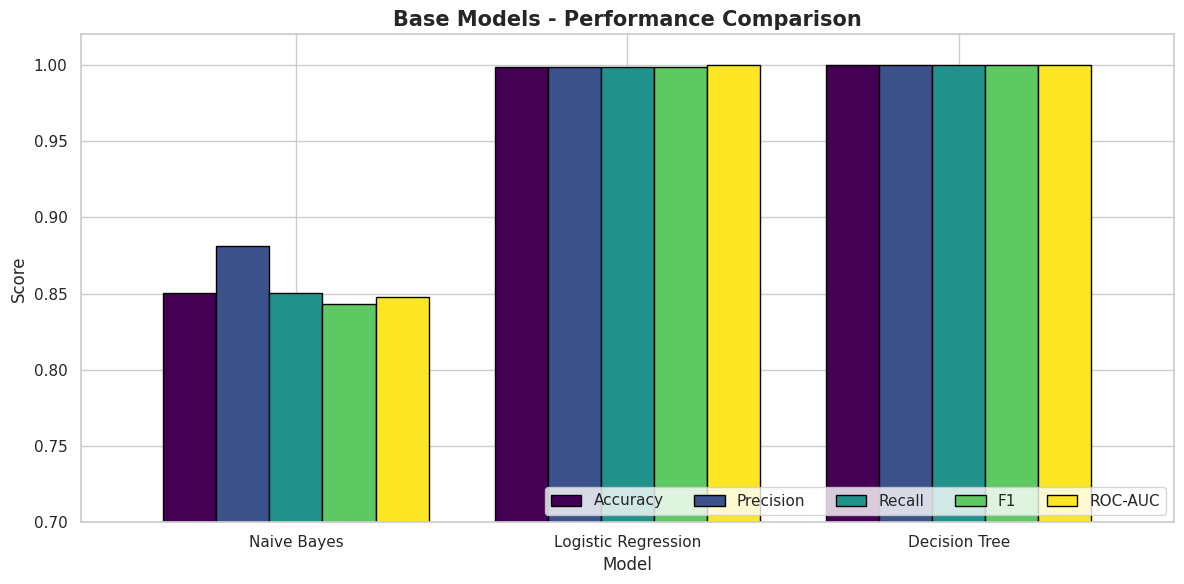

In [10]:

ax = res_base.plot(kind="bar", figsize=(12, 6), width=.8, colormap="viridis", edgecolor="black")
ax.set_ylim(0.7, 1.02); plt.xticks(rotation=0)
plt.title("Base Models - Performance Comparison"); plt.ylabel("Score")
plt.legend(loc="lower right", ncol=5); plt.tight_layout(); plt.show()

## Cell 10:Voting Ensemble + Evaluation

In [11]:
voting = VotingClassifier(
    estimators=[("NB", clone(base["Naive Bayes"])),
                ("LR", clone(base["Logistic Regression"])),
                ("DT", clone(base["Decision Tree"]))],
    voting="soft")
voting.fit(X_train_f, y_train)

results.append(evaluate("Voting (Base)", voting, X_test_f, y_test))
res_all = pd.DataFrame(results).set_index("Model")
res_all.style.background_gradient(cmap="Greens", axis=None).format("{:.4f}")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Naive Bayes,0.8504,0.8811,0.8504,0.8431,0.8478
Logistic Regression,0.9985,0.9985,0.9985,0.9985,0.9998
Decision Tree,0.9997,0.9997,0.9997,0.9997,0.9997
Voting (Base),0.9989,0.9989,0.9989,0.9989,0.9999


## Cell 11 :  Voting chart

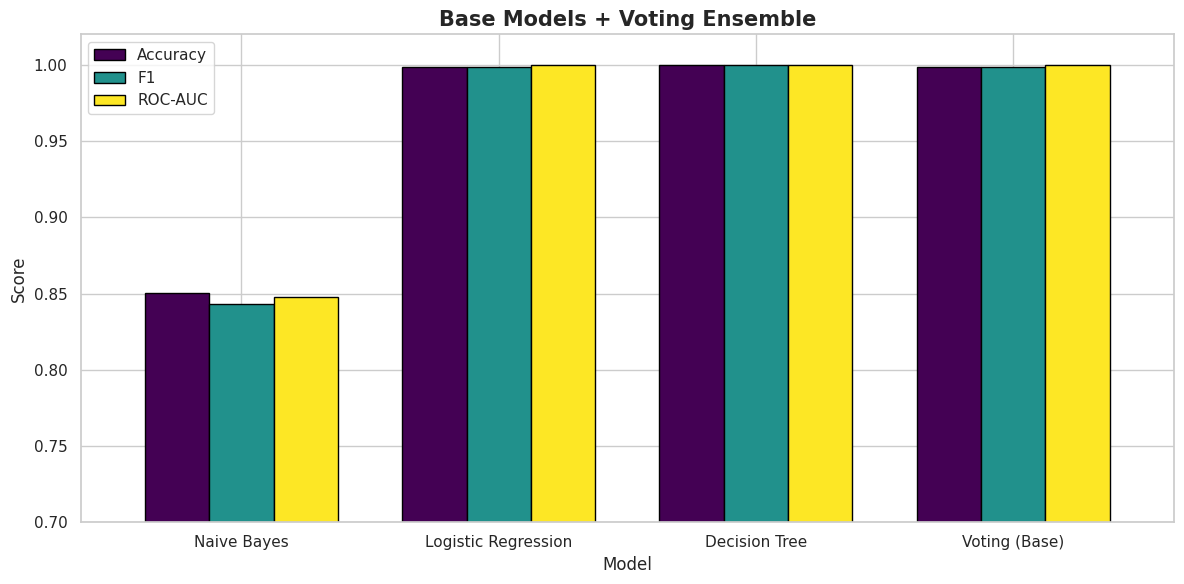

In [12]:
res_all[["Accuracy", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(12, 6), width=.75,
                                           colormap="viridis", edgecolor="black")
plt.ylim(0.7, 1.02); plt.xticks(rotation=0); plt.ylabel("Score")
plt.title("Base Models + Voting Ensemble"); plt.tight_layout(); plt.show()

## Cell 12: GridSearchCV

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

SAMPLE_N = 20_000
Xs = X_train.sample(SAMPLE_N, random_state=RS)
ys = y_train.loc[Xs.index]

def run_grid(clf, grid):
    pipe = Pipeline([("prep", make_prep()), ("clf", clf)])
    g = GridSearchCV(pipe, grid, cv=cv, scoring="f1_weighted", n_jobs=-1)
    g.fit(Xs, ys)
    return g

grid_nb = run_grid(GaussianNB(),
                   {"clf__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4]})
grid_lr = run_grid(LogisticRegression(max_iter=2000),
                   {"clf__C": [0.01, 0.1, 1, 10, 100]})
grid_dt = run_grid(DecisionTreeClassifier(random_state=RS),
                   {"clf__max_depth": [5, 10, 20, None],
                    "clf__min_samples_split": [2, 5, 10],
                    "clf__criterion": ["gini", "entropy"]})

best_params = pd.DataFrame({
    "Best parameters": [grid_nb.best_params_, grid_lr.best_params_, grid_dt.best_params_],
    "CV F1": [grid_nb.best_score_, grid_lr.best_score_, grid_dt.best_score_]},
    index=["Naive Bayes", "Logistic Regression", "Decision Tree"])
best_params.style.format({"CV F1": "{:.4f}"})

,Best parameters,CV F1
Naive Bayes,{'clf__var_smoothing': 1e-08},0.9075
Logistic Regression,{'clf__C': 100},0.9983
Decision Tree,"{'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_split': 5}",0.9994


## Cell 13:   Retrain tuned models on FULL train + Evaluation 

In [14]:
strip = lambda d: {k.replace("clf__", ""): v for k, v in d.items()}

tuned = {
    "Naive Bayes (Tuned)":         GaussianNB(**strip(grid_nb.best_params_)),
    "Logistic Regression (Tuned)": LogisticRegression(max_iter=2000, **strip(grid_lr.best_params_)),
    "Decision Tree (Tuned)":       DecisionTreeClassifier(random_state=RS, **strip(grid_dt.best_params_)),
}
tuned_results = []
for name, model in tuned.items():
    model.fit(X_train_f, y_train)
    tuned_results.append(evaluate(name, model, X_test_f, y_test))

voting_t = VotingClassifier(
    estimators=[("NB", clone(tuned["Naive Bayes (Tuned)"])),
                ("LR", clone(tuned["Logistic Regression (Tuned)"])),
                ("DT", clone(tuned["Decision Tree (Tuned)"]))],
    voting="soft")
voting_t.fit(X_train_f, y_train)
tuned_results.append(evaluate("Voting (Tuned)", voting_t, X_test_f, y_test))

res_tuned = pd.DataFrame(tuned_results).set_index("Model")
res_tuned.style.background_gradient(cmap="Blues", axis=None).format("{:.4f}")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Naive Bayes (Tuned),0.8512,0.8816,0.8512,0.8441,0.8514
Logistic Regression (Tuned),0.9990,0.9990,0.9990,0.9990,0.9999
Decision Tree (Tuned),0.9998,0.9998,0.9998,0.9998,0.9999
Voting (Tuned),0.9993,0.9993,0.9993,0.9993,0.9999


## Cell 14: Before vs After Tuning

,F1 before,F1 after,Acc before,Acc after,F1 change
Naive Bayes,0.8431,0.8441,0.8504,0.8512,0.0010
Logistic Regression,0.9985,0.9990,0.9985,0.9990,0.0005
Decision Tree,0.9997,0.9998,0.9997,0.9998,0.0001
Voting,0.9989,0.9993,0.9989,0.9993,0.0004


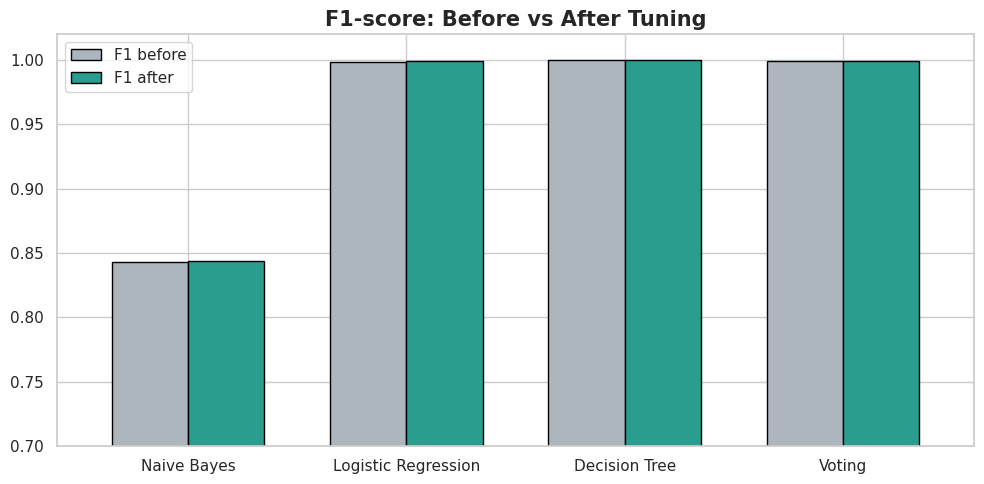

In [15]:
pairs = [("Naive Bayes", "Naive Bayes (Tuned)"), ("Logistic Regression", "Logistic Regression (Tuned)"),
         ("Decision Tree", "Decision Tree (Tuned)"), ("Voting (Base)", "Voting (Tuned)")]
cmp = pd.DataFrame({
    "F1 before":  [res_all.loc[a, "F1"] for a, b in pairs],
    "F1 after":   [res_tuned.loc[b, "F1"] for a, b in pairs],
    "Acc before": [res_all.loc[a, "Accuracy"] for a, b in pairs],
    "Acc after":  [res_tuned.loc[b, "Accuracy"] for a, b in pairs]},
    index=[a.replace(" (Base)", "") for a, b in pairs])
cmp["F1 change"] = cmp["F1 after"] - cmp["F1 before"]
display(cmp.style.format("{:.4f}").background_gradient(subset=["F1 change"], cmap="RdYlGn", axis=None))

cmp[["F1 before", "F1 after"]].plot(kind="bar", figsize=(10, 5), width=.7,
                                    color=["#adb5bd", "#2a9d8f"], edgecolor="black")
plt.ylim(0.7, 1.02); plt.xticks(rotation=0); plt.title("F1-score: Before vs After Tuning")
plt.tight_layout(); plt.show()

## 

## Cell 15:  Final Comparison + Best Model


In [16]:

final_res = pd.concat([res_all, res_tuned]).sort_values(["F1", "ROC-AUC"], ascending=False)
display(final_res.style.background_gradient(cmap="Greens", axis=None).format("{:.4f}"))

all_models = {**base, "Voting (Base)": voting, **tuned, "Voting (Tuned)": voting_t}
best_name  = final_res.index[0]
best_model = all_models[best_name]
display(Markdown(f"### 🥇 Best model: **{best_name}**  -  "
                 f"Accuracy = {final_res.loc[best_name,'Accuracy']:.4f}, "
                 f"F1 = {final_res.loc[best_name,'F1']:.4f}, "
                 f"ROC-AUC = {final_res.loc[best_name,'ROC-AUC']:.4f}"))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Decision Tree (Tuned),0.9998,0.9998,0.9998,0.9998,0.9999
Decision Tree,0.9997,0.9997,0.9997,0.9997,0.9997
Voting (Tuned),0.9993,0.9993,0.9993,0.9993,0.9999
Logistic Regression (Tuned),0.9990,0.9990,0.9990,0.9990,0.9999
Voting (Base),0.9989,0.9989,0.9989,0.9989,0.9999
Logistic Regression,0.9985,0.9985,0.9985,0.9985,0.9998
Naive Bayes (Tuned),0.8512,0.8816,0.8512,0.8441,0.8514
Naive Bayes,0.8504,0.8811,0.8504,0.8431,0.8478


### 🥇 Best model: **Decision Tree (Tuned)**  -  Accuracy = 0.9998, F1 = 0.9998, ROC-AUC = 0.9999

## Cell 16: Classification Report + Confusion Matrix

              precision    recall  f1-score   support

      BENIGN     0.9995    0.9999    0.9997     19019
        DDoS     1.0000    0.9996    0.9998     25604

    accuracy                         0.9998     44623
   macro avg     0.9997    0.9998    0.9998     44623
weighted avg     0.9998    0.9998    0.9998     44623



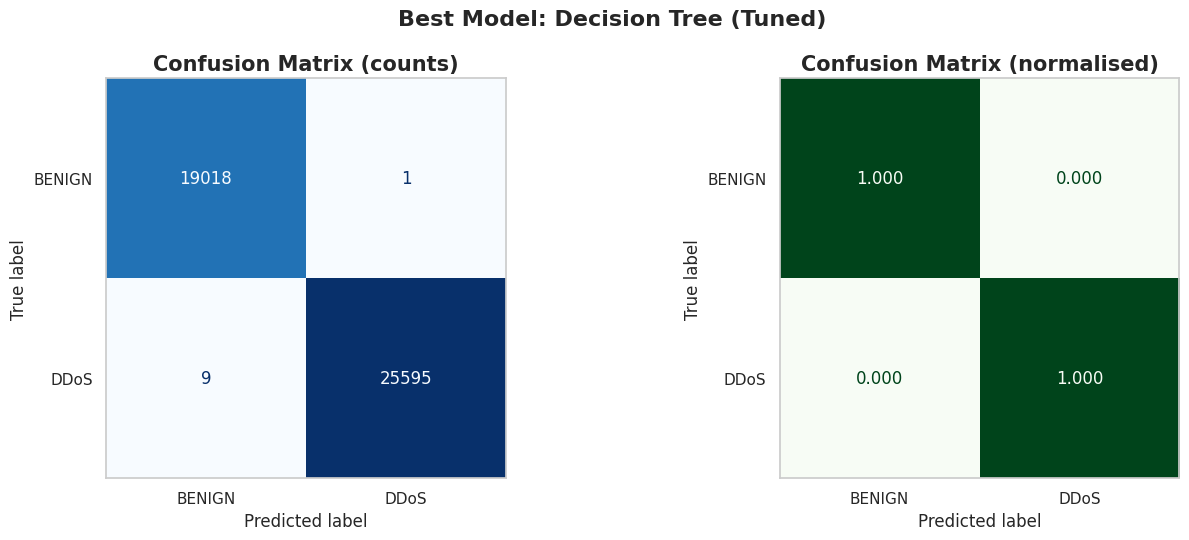

In [17]:

y_pred = best_model.predict(X_test_f)
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES,
                                        cmap="Blues", values_format="d", ax=ax[0], colorbar=False)
ax[0].set_title("Confusion Matrix (counts)"); ax[0].grid(False)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES, normalize="true",
                                        cmap="Greens", values_format=".3f", ax=ax[1], colorbar=False)
ax[1].set_title("Confusion Matrix (normalised)"); ax[1].grid(False)
plt.suptitle(f"Best Model: {best_name}", fontsize=16, fontweight="bold")
plt.tight_layout(); plt.show()

## Cell 17: K-Fold Cross-Validation

Fold accuracies : [0.9998 0.9998 0.9997 0.9998 0.9999]
CV mean ± std   : 0.9998 ± 0.0001
Test accuracy   : 0.9998
Difference      : 0.0000  (0.00 %)   limit = 0.005
Result          : ✅ PASS - no overfitting


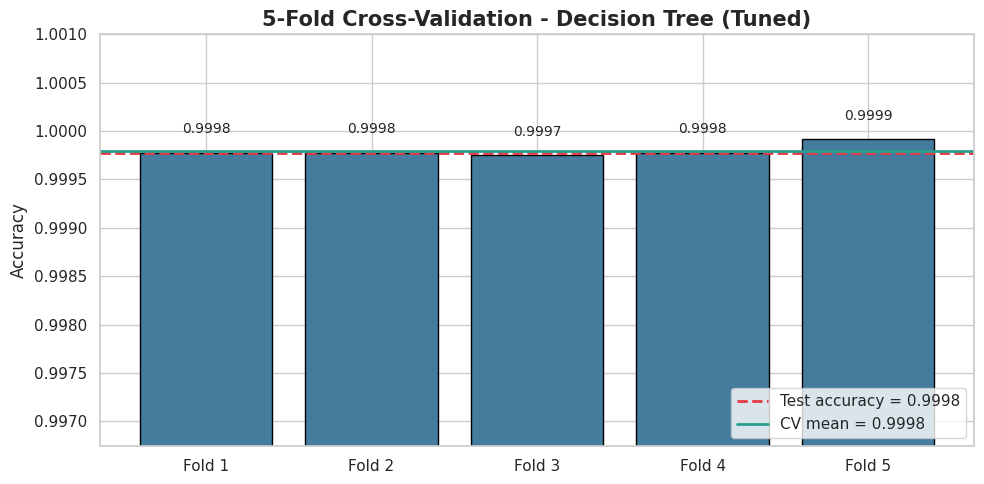

In [18]:

cv_pipe = Pipeline([("prep", make_prep()), ("clf", clone(best_model))])
cv_scores = cross_val_score(cv_pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)

test_acc = accuracy_score(y_test, best_model.predict(X_test_f))
gap = abs(cv_scores.mean() - test_acc)

print("Fold accuracies :", np.round(cv_scores, 4))
print(f"CV mean ± std   : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"Test accuracy   : {test_acc:.4f}")
print(f"Difference      : {gap:.4f}  ({gap*100:.2f} %)   limit = {GAP_LIMIT}")
print("Result          :", "✅ PASS - no overfitting" if gap <= GAP_LIMIT else "⚠️ FAIL - possible overfitting")

plt.figure(figsize=(10, 5))
bars = plt.bar([f"Fold {i+1}" for i in range(len(cv_scores))], cv_scores, color="#457b9d", edgecolor="black")
plt.axhline(test_acc, color="#e63946", ls="--", lw=2, label=f"Test accuracy = {test_acc:.4f}")
plt.axhline(cv_scores.mean(), color="#2a9d8f", ls="-", lw=2, label=f"CV mean = {cv_scores.mean():.4f}")
for b, s in zip(bars, cv_scores):
    plt.text(b.get_x() + b.get_width()/2, s + 0.0002, f"{s:.4f}", ha="center", fontsize=10)
plt.ylim(cv_scores.min() - 0.003, 1.001)
plt.title(f"5-Fold Cross-Validation - {best_name}"); plt.ylabel("Accuracy"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

## Cell 18: ROC Curve + AUC 

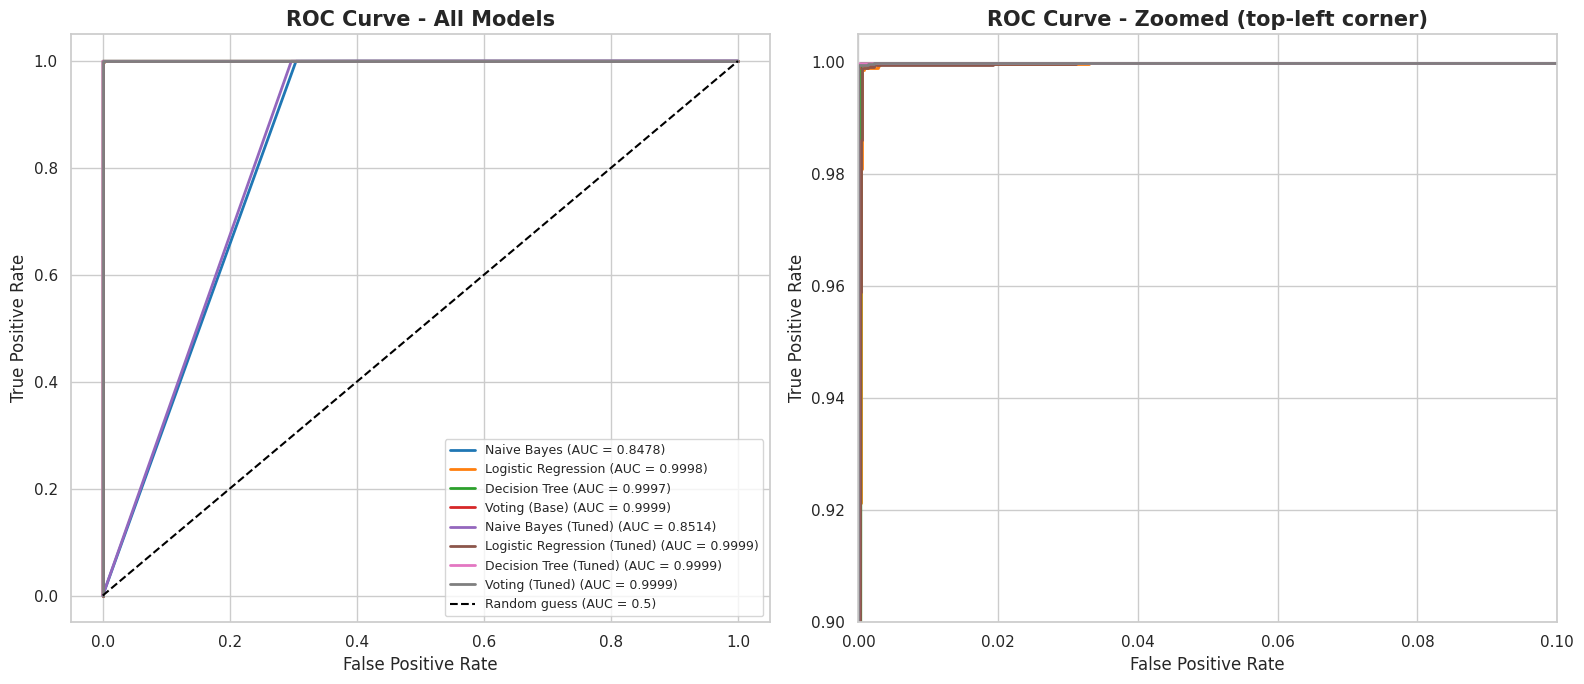

In [19]:

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
palette = sns.color_palette("tab10", len(all_models))
for (name, model), col in zip(all_models.items(), palette):
    proba = model.predict_proba(X_test_f)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    for a in ax:
        a.plot(fpr, tpr, lw=2, color=col, label=f"{name} (AUC = {auc(fpr, tpr):.4f})")

ax[0].plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
ax[0].set_title("ROC Curve - All Models")
ax[1].set_xlim(0, 0.1); ax[1].set_ylim(0.9, 1.005)
ax[1].set_title("ROC Curve - Zoomed (top-left corner)")
for a in ax:
    a.set_xlabel("False Positive Rate"); a.set_ylabel("True Positive Rate")
ax[0].legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

## Cell 19: XAI

In [20]:

bg  = shap.sample(X_train_f, 100, random_state=RS)
Xex = X_test_f.sample(200, random_state=RS)

def predict_ddos(d):
    return best_model.predict_proba(pd.DataFrame(d, columns=selected))[:, 1]

explainer = shap.Explainer(predict_ddos, bg)
sv = explainer(Xex)
print("SHAP values computed:", sv.values.shape)

PermutationExplainer explainer: 201it [00:15, 10.92it/s]                         


SHAP values computed: (200, 25)


## Cell 20 : SHAP summary 

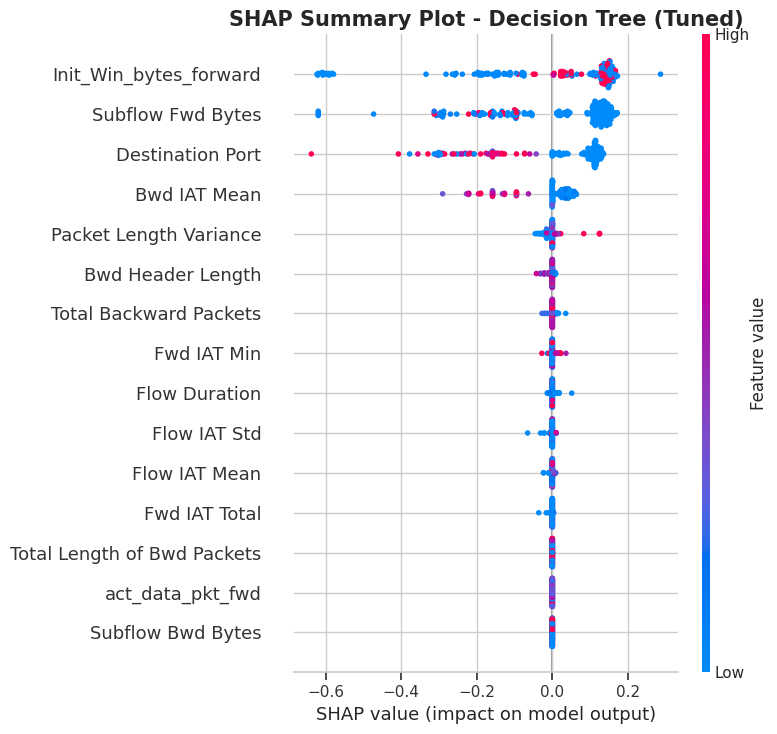

In [21]:

shap.summary_plot(sv.values, Xex, max_display=15, show=False)
plt.title("SHAP Summary Plot - " + best_name); plt.tight_layout(); plt.show()